# 03 · MPC and iterative MPC

> **In short:** the CVXPY controller solves a QP over a 2.4 s horizon. Because the model is linearized around a guess, it re-linearizes around each new solution (iterative MPC) until the plan stops changing.
>
> **Runtime:** about 15 s · **Read alongside:** [Theory 11 · MPC](../1.Docs/Theory/11_MPC.md) · [Theory 12 · CC-MPC](../1.Docs/Theory/12_CCMPC.md) · [ODE experiments](../2.Code/docs/guides/ode-experiments.md)

**You will:**

- solve one CC-MPC problem with `quadrotor_mpc.control.ccmpc.CCMPC`
- plot the planned horizon around an ellipsoidal obstacle
- measure how fast the iMPC iterations converge

## The optimization problem

$$\min_{u_{0:N-1}}\ \|p_N-p_g\|^2_{Q_g}+\sum_{k}\|R^{1/2}u_k\|^2+Q_\psi\sum_k(\psi_k-\bar\psi_k)^2+\text{slack penalty}$$

subject to the affine dynamics $x_{k+1}=A_kx_k+B_ku_k+C_k$, actuator and state bounds and one
softened chance constraint per obstacle and step (notebook 04). Weights, horizon and limits come from
`config/controller.yaml`.

**iMPC:** guess a trajectory → linearize along it → solve the QP → use the solution as the new guess →
repeat until the largest change is below `prediction.tolerance` or `prediction.max_iter` is reached.

In [1]:
from nbsetup import *

In [2]:
import copy
import time

import yaml

from quadrotor_mpc.application.simulation.config import load_scenario
from quadrotor_mpc.control.ccmpc.ccmpc import CCMPC
from quadrotor_mpc.control.ccmpc.obstacle import EllipsoidalObstacle, ObstacleManager

scenario = load_scenario(CONFIG / "scenarios" / "static_obstacle.yaml")
base_config = yaml.safe_load((CONFIG / "controller.yaml").read_text())
x0 = np.asarray(scenario.start, dtype=float)
goal = np.asarray(scenario.goal, dtype=float)
spec = scenario.obstacles[0]


def obstacles():
    return ObstacleManager([
        EllipsoidalObstacle(
            position=spec.position, size=spec.size, yaw=spec.yaw, velocity=spec.velocity,
            pos_uncertainty=spec.pos_uncertainty, vel_uncertainty=spec.vel_uncertainty,
        )
    ])


def solve(max_iter, delta=None):
    config = copy.deepcopy(base_config)
    config["controller"]["prediction"]["max_iter"] = max_iter
    config["controller"]["prediction"]["tolerance"] = 1e-9  # force exactly max_iter iterations
    if delta is not None:
        config["controller"]["obstacle"]["delta"] = delta
    controller = CCMPC(config)
    started = time.perf_counter()
    states, controls = controller.solve(x0, goal, obstacle_manager=obstacles())
    return states, controls, (time.perf_counter() - started) * 1e3, controller


plan, controls, elapsed_ms, controller = solve(max_iter=6)
print(f"horizon: {controller.control_horizon} steps x {controller.dt} s; solve time {elapsed_ms:.0f} ms")

horizon: 40 steps x 0.06 s; solve time 929 ms


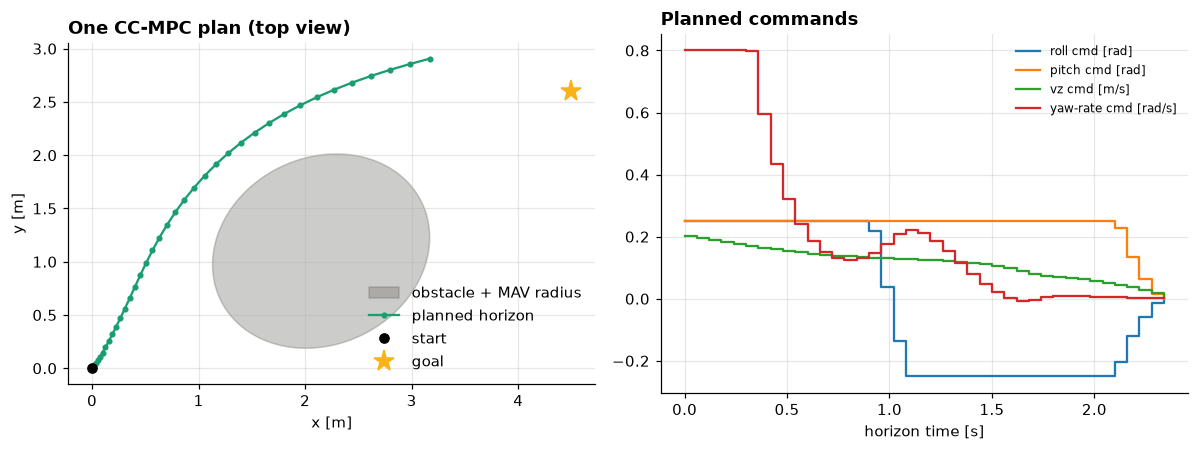

In [3]:
omega = obstacles().obstacles[0].get_omega(controller.mav_radius)
fig, (ax_top, ax_u) = plt.subplots(1, 2, figsize=(11, 4.2))
ax_top.fill(*ellipse_outline(omega, spec.position), color=NEUTRAL, alpha=0.35, label="obstacle + MAV radius")
ax_top.plot(plan[0], plan[1], "o-", ms=3, color=CONTROLLER_COLORS["ccmpc"], label="planned horizon")
ax_top.plot(*x0[:2], "ko", label="start")
ax_top.plot(*goal[:2], "*", ms=14, color="#fab219", label="goal")
ax_top.set(title="One CC-MPC plan (top view)", xlabel="x [m]", ylabel="y [m]", aspect="equal")
ax_top.legend(loc="lower right")
time_axis = np.arange(controls.shape[1]) * controller.dt
for row, name in enumerate(["roll cmd [rad]", "pitch cmd [rad]", "vz cmd [m/s]", "yaw-rate cmd [rad/s]"]):
    ax_u.step(time_axis, controls[row], where="post", label=name)
ax_u.set(title="Planned commands", xlabel="horizon time [s]")
ax_u.legend(fontsize=8)
plt.tight_layout()
plt.show()

## How fast does iMPC converge?

Solve the same problem with 1, 2, … iterations and compare consecutive plans.

iteration 1 -> 2: largest state change 1.85e+00
iteration 2 -> 3: largest state change 4.94e-01
iteration 3 -> 4: largest state change 3.31e-02
iteration 4 -> 5: largest state change 4.68e-03
iteration 5 -> 6: largest state change 1.02e-03
iteration 6 -> 7: largest state change 1.79e-04
iteration 7 -> 8: largest state change 4.36e-05


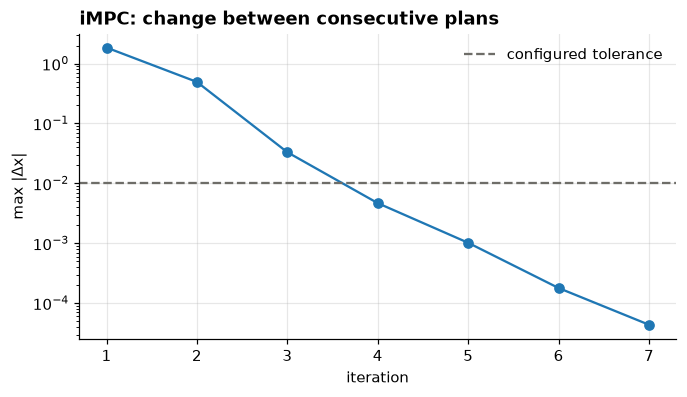

In [4]:
plans = {k: solve(max_iter=k)[0] for k in range(1, 9)}
changes = [np.abs(plans[k + 1] - plans[k]).max() for k in range(1, 8)]
for k, change in enumerate(changes, start=1):
    print(f"iteration {k} -> {k + 1}: largest state change {change:.2e}")

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.semilogy(range(1, 8), changes, "o-")
ax.axhline(base_config["controller"]["prediction"]["tolerance"], color=NEUTRAL, ls="--",
           label="configured tolerance")
ax.set(title="iMPC: change between consecutive plans", xlabel="iteration", ylabel="max |Δx|")
ax.legend()
plt.show()
assert changes[-1] < changes[0] * 1e-2

## Takeaways

- The first linearization (straight line toward the goal) is far from the final plan; two or three
  re-linearizations reduce the change by orders of magnitude.
- In closed loop the previous plan, shifted by one step, is the warm start, so fewer iterations are
  needed per tick.
- The chance constraint that keeps the plan away from the obstacle is the subject of the next notebook.

---

**Previous:** [02_ode_linearization.ipynb](02_ode_linearization.ipynb) · **Next:** [04_chance_constraints.ipynb](04_chance_constraints.ipynb)